In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
import mahotas
warnings.filterwarnings("ignore")

In [3]:
GROUP = "C2"
DTYPE="HRLK"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C2_10,27,"[DATA/TRAINING/C2/C2_10/IMG_6566.HEIC, DATA/TR..."
1,C2_11,25,"[DATA/TRAINING/C2/C2_11/IMG_6666.HEIC, DATA/TR..."
2,C2_12,25,"[DATA/TRAINING/C2/C2_12/IMG_6789.HEIC, DATA/TR..."
3,C2_13,29,"[DATA/TRAINING/C2/C2_13/IMG_6944.HEIC, DATA/TR..."
4,C2_14,25,"[DATA/TRAINING/C2/C2_14/IMG_7189.HEIC, DATA/TR..."
5,C2_15,28,"[DATA/TRAINING/C2/C2_15/IMG_7315.HEIC, DATA/TR..."
6,C2_16,28,"[DATA/TRAINING/C2/C2_16/IMG_7447.HEIC, DATA/TR..."


In [4]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [5]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [6]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_6566.HEIC')

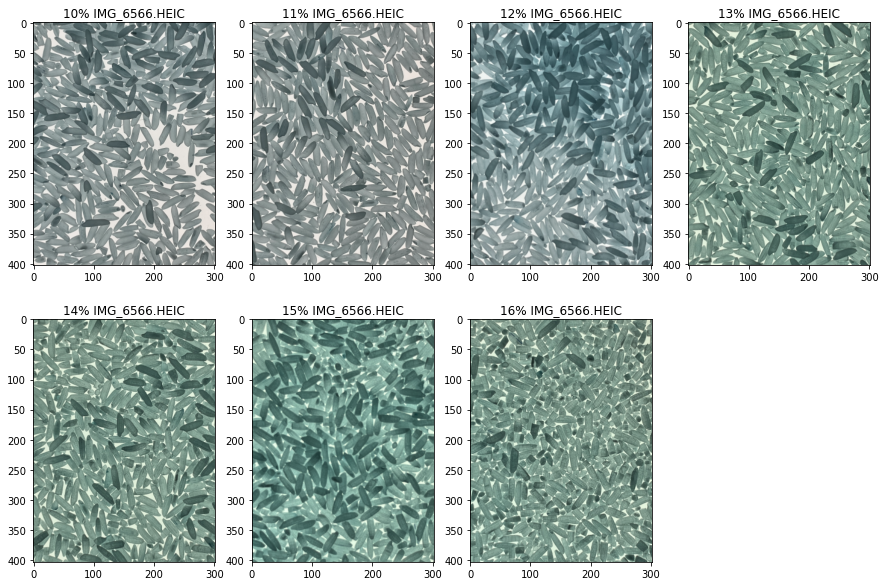

In [7]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][0].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[0][0].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[0][0].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[0][0].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[0][0].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[0][0].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[0][0].split("/")[4])

In [153]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [154]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.000210,695.325375,0.688804,1117.182118,0.089743,276.123127,3773.403098,7.901655,12.668122,0.000108,...,0.000075,5.939865,-0.160630,0.945909,3,120,90,3,IMG_6566.HEIC,10
1,0.000239,839.658333,0.623325,1114.567370,0.085591,288.821067,3618.611148,7.817246,12.604289,0.000097,...,0.000069,6.053365,-0.147086,0.932175,3,120,90,3,IMG_6567.HEIC,10
2,0.000263,816.636423,0.630713,1105.692429,0.088215,289.743727,3606.133294,7.804350,12.535139,0.000099,...,0.000082,5.917210,-0.160948,0.943762,3,120,90,3,IMG_6568.HEIC,10
3,0.000237,811.595693,0.646006,1146.340280,0.087675,287.382584,3773.765427,7.844815,12.611732,0.000099,...,0.000069,6.061221,-0.149940,0.935289,3,120,90,3,IMG_6569.HEIC,10
4,0.000279,839.416292,0.574061,985.372296,0.087656,288.250749,3102.072893,7.690011,12.432125,0.000099,...,0.000077,5.963167,-0.140978,0.922884,3,120,90,3,IMG_6570.HEIC,10
5,0.000240,759.262079,0.644998,1069.378530,0.092744,286.317884,3518.252040,7.825784,12.576330,0.000104,...,0.000080,5.903966,-0.158284,0.942374,3,120,90,3,IMG_6571.HEIC,10
6,0.000291,903.518165,0.552453,1009.411519,0.091574,289.551124,3134.127911,7.672079,12.414008,0.000098,...,0.000076,5.994906,-0.141233,0.922750,3,120,90,3,IMG_6572.HEIC,10
7,0.000220,800.386142,0.660777,1179.734335,0.093069,283.910674,3918.551197,7.886506,12.661712,0.000100,...,0.000070,6.034957,-0.151353,0.937320,3,120,90,3,IMG_6573.HEIC,10
8,0.000235,801.129682,0.629410,1080.884392,0.089521,286.287172,3522.407888,7.810218,12.600839,0.000102,...,0.000077,5.961960,-0.150882,0.935669,3,120,90,3,IMG_6574.HEIC,10
9,0.000226,763.897285,0.674352,1172.887465,0.098412,283.524625,3927.652577,7.885701,12.629630,0.000104,...,0.000069,6.043388,-0.149716,0.935684,3,120,90,3,IMG_6575.HEIC,10


# Classification

In [155]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [156]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [157]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [158]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [159]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [160]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.631579,0.666667,0.619048,0.641975,HRLK,C2,RF_C,3,120,90,3
1,2,0.631579,0.723810,0.666667,0.694064,HRLK,C2,RF_C,3,120,90,3
2,3,0.631579,0.671429,0.619048,0.644175,HRLK,C2,RF_C,3,120,90,3
3,4,0.578947,0.607143,0.571429,0.588745,HRLK,C2,RF_C,3,120,90,3
4,5,0.473684,0.511905,0.476190,0.493402,HRLK,C2,RF_C,3,120,90,3
5,6,0.473684,0.380952,0.476190,0.423280,HRLK,C2,RF_C,3,120,90,3
6,7,0.473684,0.464286,0.500000,0.481481,HRLK,C2,RF_C,3,120,90,3
7,8,0.555556,0.514286,0.547619,0.530429,HRLK,C2,RF_C,3,120,90,3
8,9,0.722222,0.809524,0.738095,0.772161,HRLK,C2,RF_C,3,120,90,3
9,10,0.611111,0.738095,0.666667,0.700565,HRLK,C2,RF_C,3,120,90,3


In [161]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C2,RF_C,0.578363,0.588095,0.597028,0.60881


### MLP Classifier

In [133]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [134]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [135]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.736842,0.723810,0.761905,0.742369,HRLK,C2,MLP_C,5,201,151,3
1,2,0.526316,0.571429,0.523810,0.546584,HRLK,C2,MLP_C,5,201,151,3
2,3,0.631579,0.619048,0.666667,0.641975,HRLK,C2,MLP_C,5,201,151,3
3,4,0.842105,0.857143,0.833333,0.845070,HRLK,C2,MLP_C,5,201,151,3
4,5,0.736842,0.823810,0.738095,0.778600,HRLK,C2,MLP_C,5,201,151,3
5,6,0.842105,0.880952,0.833333,0.856481,HRLK,C2,MLP_C,5,201,151,3
6,7,0.684211,0.726190,0.714286,0.720189,HRLK,C2,MLP_C,5,201,151,3
7,8,0.833333,0.869048,0.833333,0.850816,HRLK,C2,MLP_C,5,201,151,3
8,9,0.888889,0.916667,0.904762,0.910675,HRLK,C2,MLP_C,5,201,151,3
9,10,0.666667,0.654762,0.642857,0.648755,HRLK,C2,MLP_C,5,201,151,3


In [136]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C2,MLP_C,0.738889,0.745238,0.754152,0.764286


### XGBoost Classifier

In [137]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [138]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.578947,0.690476,0.595238,0.639330,HRLK,C2,XGB_C,5,201,151,3
1,2,0.631579,0.714286,0.642857,0.676692,HRLK,C2,XGB_C,5,201,151,3
2,3,0.684211,0.807143,0.690476,0.744265,HRLK,C2,XGB_C,5,201,151,3
3,4,0.736842,0.678571,0.714286,0.695971,HRLK,C2,XGB_C,5,201,151,3
4,5,0.684211,0.773810,0.690476,0.729772,HRLK,C2,XGB_C,5,201,151,3
5,6,0.578947,0.607143,0.595238,0.601132,HRLK,C2,XGB_C,5,201,151,3
6,7,0.526316,0.538095,0.547619,0.542815,HRLK,C2,XGB_C,5,201,151,3
7,8,0.722222,0.692857,0.690476,0.691665,HRLK,C2,XGB_C,5,201,151,3
8,9,0.611111,0.747619,0.666667,0.704826,HRLK,C2,XGB_C,5,201,151,3
9,10,0.722222,0.738095,0.714286,0.725995,HRLK,C2,XGB_C,5,201,151,3


In [139]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,HRLK,C2,XGB_C,0.647661,0.654762,0.675246,0.69881


# External validation

In [140]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C2_10,5,"[DATA/TEST/C2/C2_10/IMG_6560.HEIC, DATA/TEST/C..."
1,C2_11,5,"[DATA/TEST/C2/C2_11/IMG_6656.HEIC, DATA/TEST/C..."
2,C2_12,5,"[DATA/TEST/C2/C2_12/IMG._6813.HEIC, DATA/TEST/..."
3,C2_13,5,"[DATA/TEST/C2/C2_13/IMG_6918.HEIC, DATA/TEST/C..."
4,C2_14,5,"[DATA/TEST/C2/C2_14/IMG_7179.HEIC, DATA/TEST/C..."
5,C2_15,5,"[DATA/TEST/C2/C2_15/IMG_7305.HEIC, DATA/TEST/C..."
6,C2_16,5,"[DATA/TEST/C2/C2_16/IMG_7437.HEIC, DATA/TEST/C..."


In [141]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [142]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        haralick = mahotas.features.haralick(gray).ravel()
        arr_img_hist.append(haralick)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [143]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,scale,height,width,channels,IMAGENAME,HUMIDITY
0,0.000248,609.931774,0.755055,1245.039088,0.134987,281.504046,4370.224577,7.967932,12.717827,0.000162,...,0.000103,5.743546,-0.133542,0.920328,5,201,151,3,IMG_6560.HEIC,10
1,0.000285,561.754494,0.752919,1136.783893,0.145800,275.767164,3985.381078,7.892933,12.551730,0.000176,...,0.000109,5.692101,-0.130649,0.915125,5,201,151,3,IMG_6561.HEIC,10
2,0.000256,603.789619,0.765196,1285.732519,0.140475,273.681824,4539.140456,7.993010,12.717735,0.000168,...,0.000108,5.698950,-0.141527,0.929493,5,201,151,3,IMG_6563.HEIC,10
3,0.000268,571.160929,0.767844,1230.121103,0.137486,276.433698,4349.323481,7.951393,12.699011,0.000162,...,0.000118,5.593445,-0.147347,0.934539,5,201,151,3,IMG_6564.HEIC,10
4,0.000252,590.317479,0.784130,1367.297415,0.142480,276.099701,4878.872182,8.035995,12.713006,0.000172,...,0.000111,5.695078,-0.148108,0.936617,5,201,151,3,IMG_6565.HEIC,10
0,0.000339,710.394826,0.690563,1147.882744,0.129245,288.541758,3881.136150,7.792654,12.493745,0.000153,...,0.000100,5.816993,-0.118473,0.895148,5,201,151,3,IMG_6656.HEIC,11
1,0.000359,710.689022,0.685791,1130.918264,0.131317,286.370083,3812.984034,7.753775,12.412978,0.000157,...,0.000104,5.780073,-0.118685,0.894313,5,201,151,3,IMG_6658.HEIC,11
2,0.000257,726.294163,0.704092,1227.230283,0.120409,279.658806,4182.626970,7.888430,12.720881,0.000142,...,0.000096,5.835690,-0.120408,0.901084,5,201,151,3,IMG_6660.HEIC,11
3,0.000332,812.334992,0.674707,1248.619751,0.127901,288.692869,4182.144012,7.807570,12.515925,0.000150,...,0.000114,5.743608,-0.128924,0.909826,5,201,151,3,IMG_6661.HEIC,11
4,0.000252,665.139138,0.746866,1313.806161,0.130160,277.965937,4590.085506,7.945372,12.723235,0.000153,...,0.000126,5.571407,-0.153222,0.939478,5,201,151,3,IMG_6664.HEIC,11


In [144]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [145]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [146]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [147]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [148]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       0.50      0.20      0.29         5
     Class 2       0.45      1.00      0.62         5
     Class 3       0.80      0.80      0.80         5
     Class 4       0.33      0.40      0.36         5
     Class 5       0.25      0.20      0.22         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.51        35
   macro avg       0.48      0.51      0.47        35
weighted avg       0.48      0.51      0.47        35



## MLP

In [149]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [150]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       1.00      0.40      0.57         5
     Class 2       0.40      0.80      0.53         5
     Class 3       1.00      1.00      1.00         5
     Class 4       0.43      0.60      0.50         5
     Class 5       0.33      0.20      0.25         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.57        35
   macro avg       0.59      0.57      0.55        35
weighted avg       0.59      0.57      0.55        35



## XGBC

In [151]:
y_pred = modelXGBC.predict(X_test_scale) 

In [152]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.00      0.00      0.00         5
     Class 1       1.00      0.80      0.89         5
     Class 2       0.50      1.00      0.67         5
     Class 3       1.00      1.00      1.00         5
     Class 4       0.43      0.60      0.50         5
     Class 5       0.33      0.20      0.25         5
     Class 6       1.00      1.00      1.00         5

    accuracy                           0.66        35
   macro avg       0.61      0.66      0.62        35
weighted avg       0.61      0.66      0.62        35

